TAREA 3   CRISTOBAL SILVA      22.158.204-7

In [30]:
import numpy as np

In [31]:
import matplotlib.pyplot as plt

In [32]:

rng = np.random.default_rng(seed= 154937) 

PROBLEMA 1

In [63]:
 
def simular_transito_estrella():

    # Se define la desviacion estandar  y la disminucion del flujo durante el transito
    desviacion_estandar = 0.002 
    disminucion_flujo = 0.02 
    disminucion_flujo_2 = 0.015
    """  
    Esta funcion simula el flujo de una estrella durante un periodo de 10 años.
    Se genara un arreglo de 500 elementos entre 0 y 10, el cual simula un intervalo de 10 años. Ademas se genera un arreglo de 500 elementos con valor 1, el cual simula el flujo de la estrella durante los 10 años.
    Se agrega un flujo de ruido gaussiano, el cual simulara el transito de la estrella, se simulara entre los 4.5 y 5 años, el cual tendra una desviacion estandar de 0.002. Se agregara un flujo de ruido gaussiano a la simulacion, el cual tendra una desviacion estandar de 0.002.
    -----------

    Parametros:
    -----------

    Desviacion estandar del ruido gaussiano: 0.002
    Tiempo de transito: entre 4.5 y 5 años
    Disminucion del flujo durante el transito: 0.02
    Disminucion del transito 2 (7.0 a 7.4)
    
    ----------
    Retorna: 
    La funcion retorna un arreglo de 500 elementos que simula el flujo de la estrella durante los 10 años, con un transito simulado entre los 4.5 y 5 años, con una disminucion del flujo de 0.02 y un flujo de ruido gaussiano con desviacion estandar de 0.002.

    """

    tiempo = np.linspace(0,10, 500)# se genera un arreglo de 500 elementos entre 0 y 10 que simula intervalo de diez años, compuesto por 500 mediciones equidistantes.
    flujo_estrella = np.ones_like(tiempo)# se genera un arreglo de 500 elementos con valor 1 que simula el flujo de la estrella durante los 10 años.

    # Se genera un flujo de ruido gaussiano con desviacion estandar de 0.002 y se agrega al flujo de la estrella
    ruido = np.random.normal(0, desviacion_estandar, len(tiempo)) 
    flujo = flujo_estrella + ruido 

    # Guardamos una copia del flujo sin tránsitos para calcular el ruido limpio
    
    flujo_base_ruido = flujo.copy()
    
    
    # Se simula el transito de la estrella entre los 4.5 y 5 años, disminuyendo el flujo en 0.02
    mascara_transito = (tiempo >= 4.5) & (tiempo <= 5)
    flujo[mascara_transito] -= disminucion_flujo

    # Segunda mascara, que simula el transito de la estrella entre los 7 y 7.4 años
    mascara_2 = (tiempo >= 7) & (tiempo <=7.4)
    flujo[mascara_2] -= disminucion_flujo_2



    return tiempo, flujo, flujo_base_ruido



In [ ]:


def curva_luz_grafica(tiempo, flujo, flujo_base_ruido):
    """ 
    -------
    Esta funcion nos permitira mostrar la grafica con los datos solicitados, se utilizara la funcion anterior para los parametros, destacando los puntos que superan el umbral del transito
    -------
    -------
    Parametros:
    Tiempo: se utilizara lo calculado en la funcion anterior
    Flujo: se utiliza lo calculado en la funcion anterior 
    -------
    -------
    Retorna:
    Esta funcion no retorna valores explicitos, pero nos entregara la visualizacion grafica del problema utilizando matplotlib.pyplot
    -------
    """

    # Calcula el promedio y la desviacion estandar del flujo de base/ruido
    promedio_flujo = np.mean(flujo_base_ruido)
    desviacion_estandar = np.std(flujo_base_ruido)
    print("Desviación estándar:", desviacion_estandar)

    # Calcular el umbral de deteccion (F_media - 3 x sigma)
    umbral = promedio_flujo - (3 * desviacion_estandar)

    # Las condiciones deben evaluar si cumplen c
    condicion_normal = flujo >= umbral
    condicion = flujo < umbral
    
    # Se imprimen para probar los parametros calculados
    print("Total de puntos:", len(flujo))
    print("Puntos normales:", np.sum(condicion_normal))
    print("Puntos en tránsito detectados:", np.sum(condicion))
    print(f"Flujo medio: {promedio_flujo:.5f} | Umbral: {umbral:.5f}")

    # Crear figura
    plt.figure(figsize=(12, 6)) # se define el ancho y largo de la figura
    
    # Puntos que cumplen la condicion Normal (Se quitó el [0] sobrante en plt.plot)
    plt.plot(tiempo[condicion_normal], flujo[condicion_normal], "o", color="red", markersize=4, label="Flujo Normal")

    # Puntos que cumplen la condición de transito (F < umbral)
    plt.plot(tiempo[condicion], flujo[condicion], "o", color="blue", markersize=6, label="Transito (F < umbral)")

    # Lineas horizontales 
    linea_media = plt.axhline(promedio_flujo, color="green", linestyle="--", label=f"Flujo medio = {promedio_flujo:.4f}")
    linea_umbral = plt.axhline(umbral, color="orange", linestyle="--", label=f"Umbral = {umbral:.4f}")

    # Lineas verticales que muestran el primer Transito (4.5 a 5.0)
    plt.axvline(4.5, color="purple", linestyle=":", alpha=0.8, label="Transito 1 (inicio)")
    plt.axvline(5.0, color="purple", linestyle=":", alpha=0.8, label="Transito 1 (fin)")

    # Lineas verticales que muestran el segundo Transito (7.0 a 7.4)
    plt.axvline(7.0, color="brown", linestyle=":", alpha=0.8, label="Transito 2 (inicio)")
    plt.axvline(7.4, color="brown", linestyle=":", alpha=0.8, label="Transito 2 (fin)")

    # Nombra el eje Y e X
    plt.xlabel("Tiempo", fontsize=14)
    plt.ylabel("Flujo Normalizado", fontsize=14)

    # Titulo de la gráfica
    plt.title("Simulacion flujo y transito de planetas", fontsize=16, pad=15)
    
    # Cuadricula y diseño general
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.legend(
  
        fontsize=12,
        loc="lower left",
        frameon=True,
        facecolor="white",
        framealpha=0.9,
    )

    # Mostrar la gráfica
    plt.show()




            





Desviación estándar: 0.0019560122608655965
Total de puntos: 500
Puntos normales: 454
Puntos en tránsito detectados: 46
Flujo medio: 1.00000 | Umbral: 0.99413


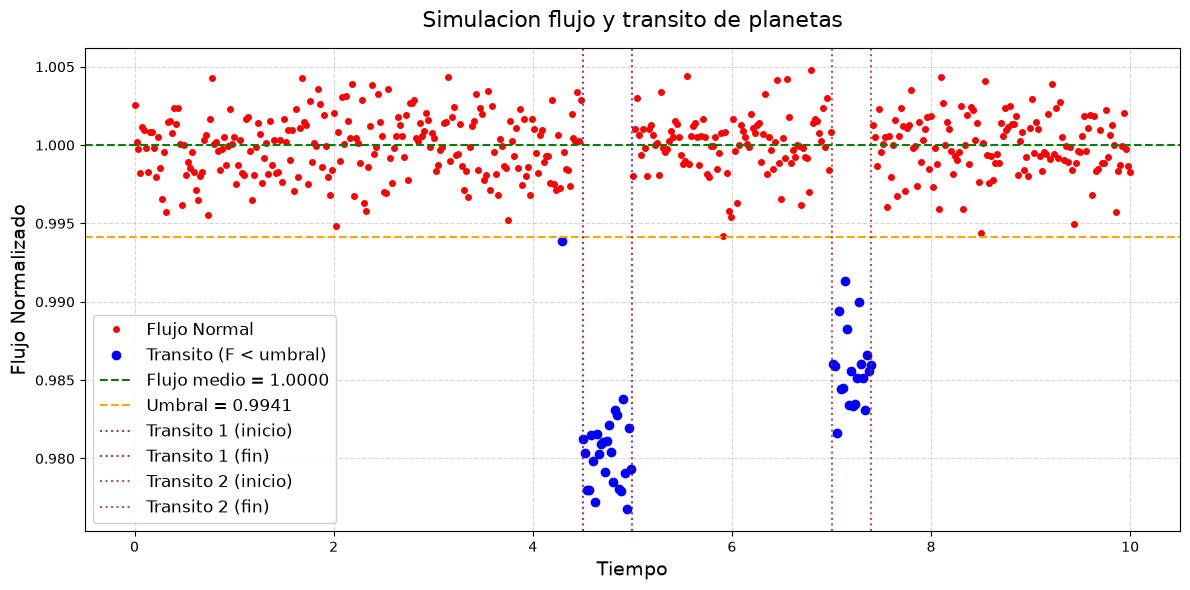

In [81]:
# Simula los datos que se utilizaran en la segunda funcion
tiempo, flujo, flujo_base_ruido = simular_transito_estrella()

# Generar la gráfica con la función creada
curva_luz_grafica(tiempo, flujo, flujo_base_ruido)




PROBLEMA 2

In [51]:
# Se definen las variables control y la configuracion inicial 
rng = np.random.default_rng(133738)
N_estrellas = 5
Io = 100
sigma = 0.5
xO= rng.uniform(-5,5, N_estrellas)
yO= rng.uniform(-5,5, N_estrellas )

# Creacion coordenadas espaciales 

nx, ny = 400, 400
x= np.linspace(-6,6, nx)
y = np.linspace(-6,6 , ny)
x2, y2= np.meshgrid(x, y)



In [52]:
print(x2,y2)

[[-6.         -5.96992481 -5.93984962 ...  5.93984962  5.96992481
   6.        ]
 [-6.         -5.96992481 -5.93984962 ...  5.93984962  5.96992481
   6.        ]
 [-6.         -5.96992481 -5.93984962 ...  5.93984962  5.96992481
   6.        ]
 ...
 [-6.         -5.96992481 -5.93984962 ...  5.93984962  5.96992481
   6.        ]
 [-6.         -5.96992481 -5.93984962 ...  5.93984962  5.96992481
   6.        ]
 [-6.         -5.96992481 -5.93984962 ...  5.93984962  5.96992481
   6.        ]] [[-6.         -6.         -6.         ... -6.         -6.
  -6.        ]
 [-5.96992481 -5.96992481 -5.96992481 ... -5.96992481 -5.96992481
  -5.96992481]
 [-5.93984962 -5.93984962 -5.93984962 ... -5.93984962 -5.93984962
  -5.93984962]
 ...
 [ 5.93984962  5.93984962  5.93984962 ...  5.93984962  5.93984962
   5.93984962]
 [ 5.96992481  5.96992481  5.96992481 ...  5.96992481  5.96992481
   5.96992481]
 [ 6.          6.          6.         ...  6.          6.
   6.        ]]


In [54]:
def generar_imagen(xO,yO,Io,sigma, x2, y2):
    """
    -----
    Funcion que genera la imagen utilizando la formula : I0 * np.exp(-((X - xi)**2 + (Y - yi)**2) / (2 * sigma**2))
    -----
    -----
    Parametros:
    N_estrellas : 5
    Io : 100
    sigma : 0.5
    xO, yO : Arreglos que contienen las coordenadas espaciales aleatorias en los ejes X e Y para el centro de cada una de las estrellas, ubicadas entre -5 y 5.
    nx, ny : INdican la cantidad de píxeles (400 X 400) que conformarán la matriz bidimensional de la imagen final.

    -----
    Retorna:
    La funcion retorna la imagen, que se calcula con la formula antes puesta 

    """
    imagen = np.zeros_like(x2, dtype= float)
    for xi, yi in zip(xO,yO ):
        imagen += Io * np.exp(-((x2 - xi)**2 + (y2- yi)**2) / (2 * sigma**2)) 
    return imagen



In [59]:
img_base = generar_imagen(xO,yO,Io, sigma, x2,y2)

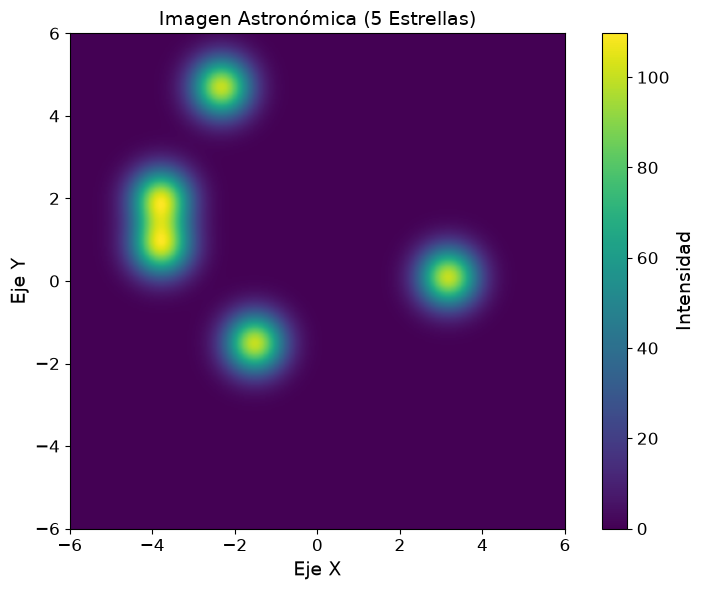

In [60]:
# Genera la imagen utilizando la informacion de la funcion anterior 
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(img_base, extent=[-6, 6, -6, 6], origin='lower', cmap='viridis')
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Intensidad', fontsize=14)
cbar.ax.tick_params(labelsize=12)

ax.set_xlabel('Eje X', fontsize=14)
ax.set_ylabel('Eje Y', fontsize=14)
ax.tick_params(axis='both', labelsize=12)
ax.set_title('Imagen Astronomica (5 Estrellas)', fontsize=14)
plt.tight_layout()
plt.show()

In [71]:
def calcular_distancias(xO, yO):
    """ 
    ------
    Funcion: 
    Combina  xO e yO en una sola matriz de puntos de (N,2), calcula las diferencias entre cada par de puntos, tambien calcula la norma euclidiana 
    ------
    ------
    Parametros:
    xO: Arreglo unidimensional (tipo NumPy array o lista) que contiene las coordenadas en el eje X de los centros de todas las estrellas.
    yO: Arreglo unidimensional que contiene las coordenadas en el eje Y de los centros de todas las estrellas.

    ------
    ------
    Retorna:
    Retorna una matriz cuadrada de (N x N), donde el elemento en las posciones (i,j) representa la distancia euclidiana

    
    """



    puntos = np.column_stack((xO, yO))
    
    diferencias = puntos[:, np.newaxis, :] - puntos[np.newaxis, :, :]
    
    
    distancias = np.linalg.norm(diferencias, axis=-1)
    
    return distancias
  

In [72]:
matriz_distancias = calcular_distancias(xO, yO)
print("Matriz de distancias euclidianas entre estrellas:", matriz_distancias)

Matriz de distancias euclidianas entre estrellas: [[0.         1.13925599 7.01786155 3.28539281 4.11867891]
 [1.13925599 0.         7.23779202 4.18621218 3.08350087]
 [7.01786155 7.23779202 0.         4.96832065 7.19080996]
 [3.28539281 4.18621218 4.96832065 0.         6.27415137]
 [4.11867891 3.08350087 7.19080996 6.27415137 0.        ]]


In [86]:
# Considerando el solapamiento, calculamos la intensidad en cada centro
intensidades = []
for i in range(N_estrellas):
    val = sum(Io * np.exp(-((xO[i] - xO[j])**2 + (yO[i] - yO[j])**2) / (2 * sigma**2)) for j in range(N_estrellas))
    intensidades.append(val)
    


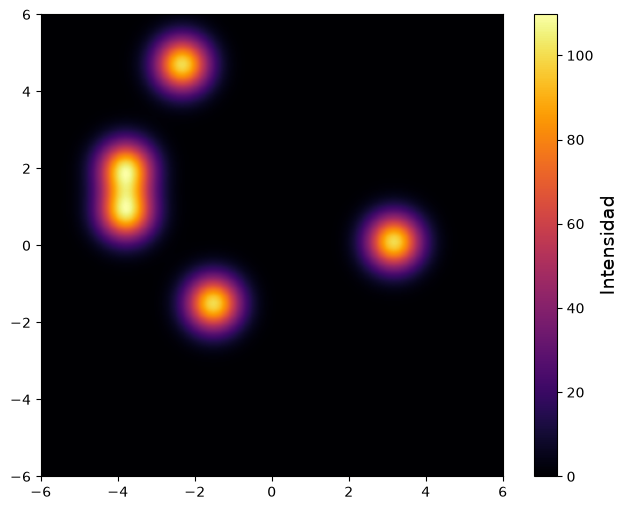

In [85]:
# Ordena y asigna un ranking en las estrellas segun su brillo y prepara la grafica 
sorted_indices = np.argsort(intensidades)
ranks = np.empty_like(sorted_indices)
ranks[sorted_indices] = np.arange(1, N_estrellas + 1)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(img_base, extent=[-6, 6, -6, 6], origin='lower', cmap='inferno')
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Intensidad', fontsize=14)
